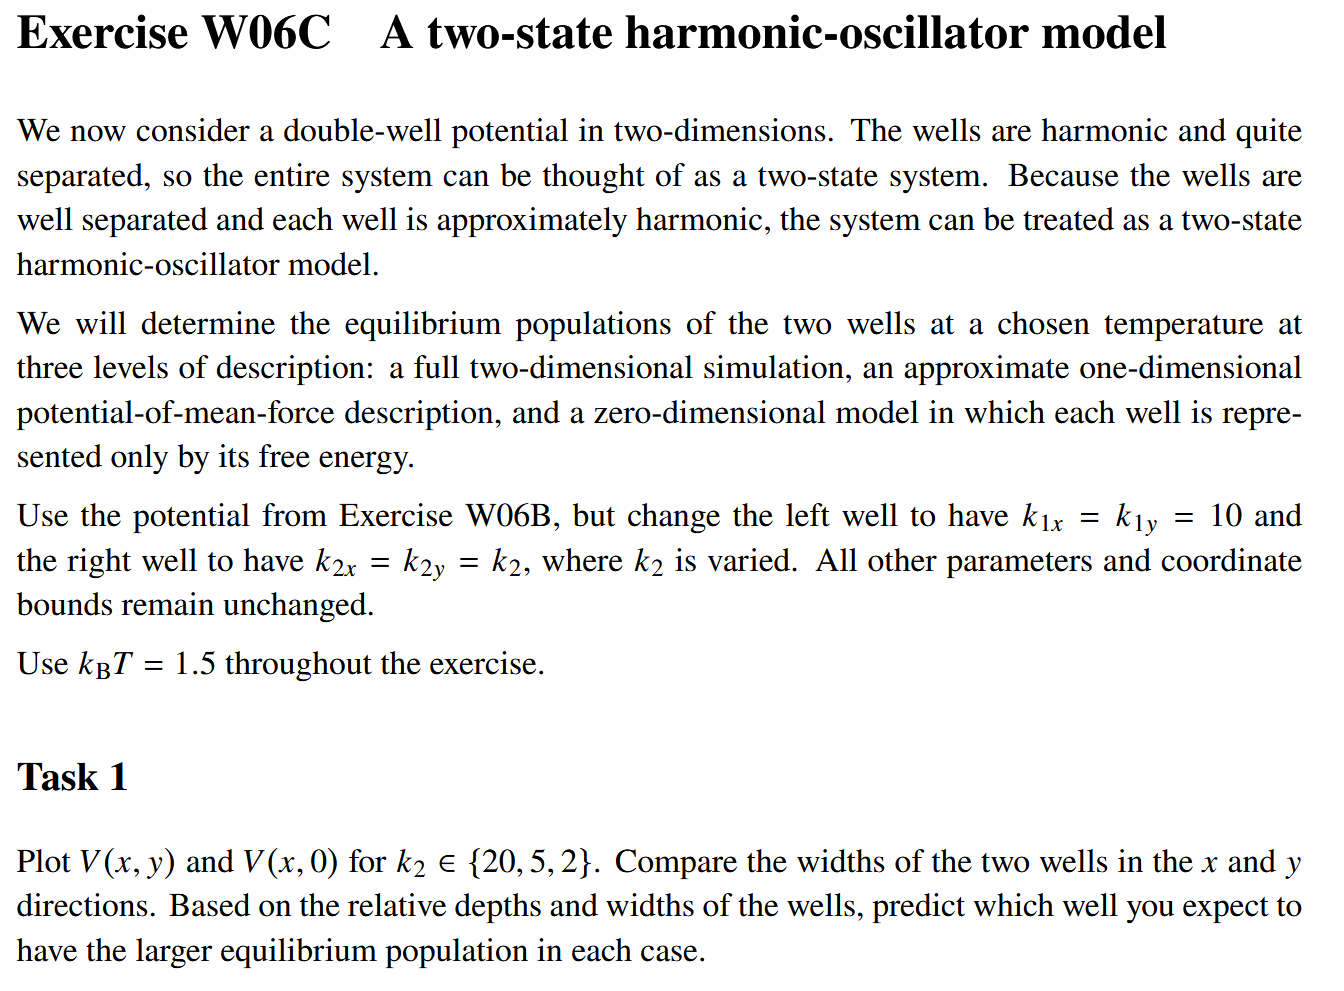

In [24]:
import numpy as np
import matplotlib.pyplot as plt 
from matplotlib import cm

class Potential2D:
    xmin = -5
    xmax = 5
    ymin = -5
    ymax = 5

    @classmethod
    def limits(cls):
        return ([cls.xmin, cls.xmax], [cls.ymin, cls.ymax])

    x1, y1 = -2.0, 0.0
    x2, y2 = 2.0, 0.0

    def __init__ (self, k1x=2.0, k1y=5.0, k2x=2.0, k2y=0.5, deltaE=1, alpha=10.0):
        self.k1x = k1x
        self.k1y = k1y
        self.k2x = k2x
        self.k2y = k2y
        self.deltaE = deltaE
        self.a = alpha

    def V1(self, x, y):
        return 0.5 * (self.k1x * (x - self.x1)**2
                    + self.k1y * (y - self.y1)**2)
    
    def V2(self, x, y):
        return 0.5 * (self.k2x * (x - self.x2)**2
                    + self.k2y * (y - self.y2)**2) + self.deltaE
    
    def V(self, state):
        x, y = state
        return -1/self.a * np.log(np.exp(-self.a*self.V1(x, y)) 
                                + np.exp(-self.a*self.V2(x,y)))
    
    def contour_of_potential_energy(self, ax):
        Nc = 50
        Xs, Ys = np.meshgrid (
            np.linspace (self.xmin, self.xmax, Nc),
            np.linspace (self.ymin, self.ymax, Nc))

        Es = self.V([Xs, Ys])
        levels = np.geomspace(1, 10, 6)
        ax.contourf(Xs, Ys, Es, levels=levels, cmap=cm.YlGnBu)
        ax.contour(Xs, Ys, Es, levels=levels, colors='k')
        ax.set_title('V(x,y)')
        ax.set_xlabel('x')
        ax.set_ylabel('y')
    
    def plot1d(self, ax, x_vals=None):
        xs = np.linspace(self.xmin, self.xmax, 1000)
        zs = self.V([xs, 0])
        ax.plot(xs, zs)
        ax.set_title('V(x ,0)')
        ax.set_xlabel('X')
        ax.set_ylim([-0.5, 13.5])

        if type(x_vals) != type(None):
            ax.set_title(f'V(x,y=0), P(x), kT={1.5}')

            # Calculate P_left and P_right
            P_left = np.sum(x_vals < 0) / len(x_vals)
            P_right = np.sum(x_vals >= 0) / len(x_vals)
            
            ax.text(-4, 11, f'$P_{{left}} = {P_left:.2f}$', color='C0', fontsize=10)
            ax.text(1, 11, f'$P_{{right}} = {P_right:.2f}$', color='C0', fontsize=10)
            
            # Plot the 1D histogram on a secondary y-axis 
            ax_twin = ax.twinx()
            ax_twin.hist(x_vals, bins=50, range=(-5, 5), density=True, alpha=0.5, edgecolor='white')
            ax_twin.set_ylim(0, 0.5) 
            ax_twin.set_yticks([])  

C:\Users\Moth\AppData\Local\Temp\ipykernel_18612\3653574842.py:36: RuntimeWarning: divide by zero encountered in log
  return -1/self.a * np.log(np.exp(-self.a*self.V1(x, y))


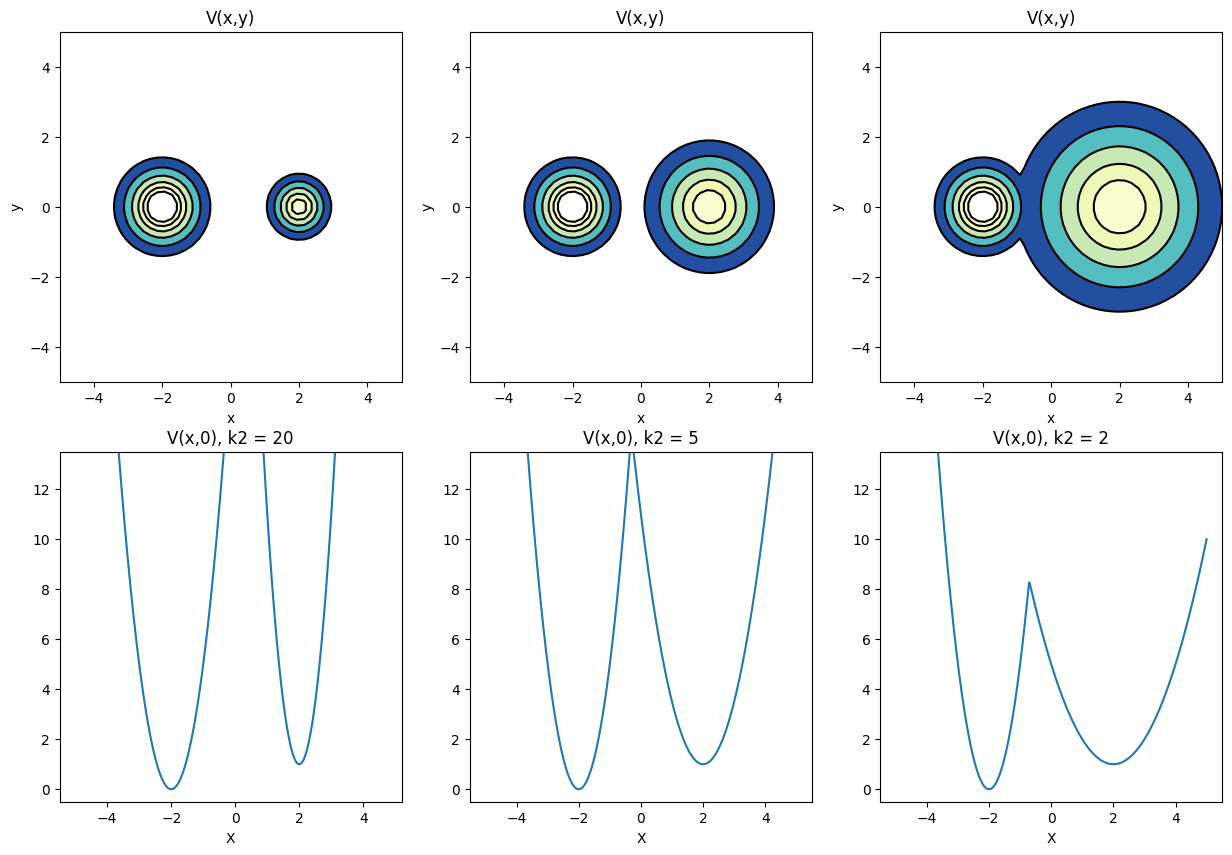

In [25]:
kbT = 1.5
k1x, k1y = 10, 10
k2_vals = [20, 5, 2]

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
ax = ax.transpose().flatten()

for i, k2 in enumerate(k2_vals):
    pot = Potential2D(k1x, k1y, k2, k2)
    pot.contour_of_potential_energy(ax[2*i])
    pot.plot1d(ax[2*i + 1])
    ax[2*i + 1].set_title(f'V(x,0), k2 = {k2}')

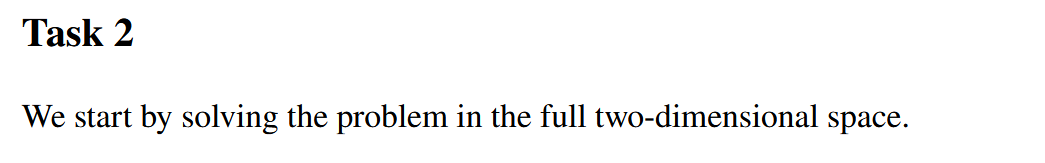

C:\Users\Moth\AppData\Local\Temp\ipykernel_18612\3653574842.py:36: RuntimeWarning: divide by zero encountered in log
  return -1/self.a * np.log(np.exp(-self.a*self.V1(x, y))


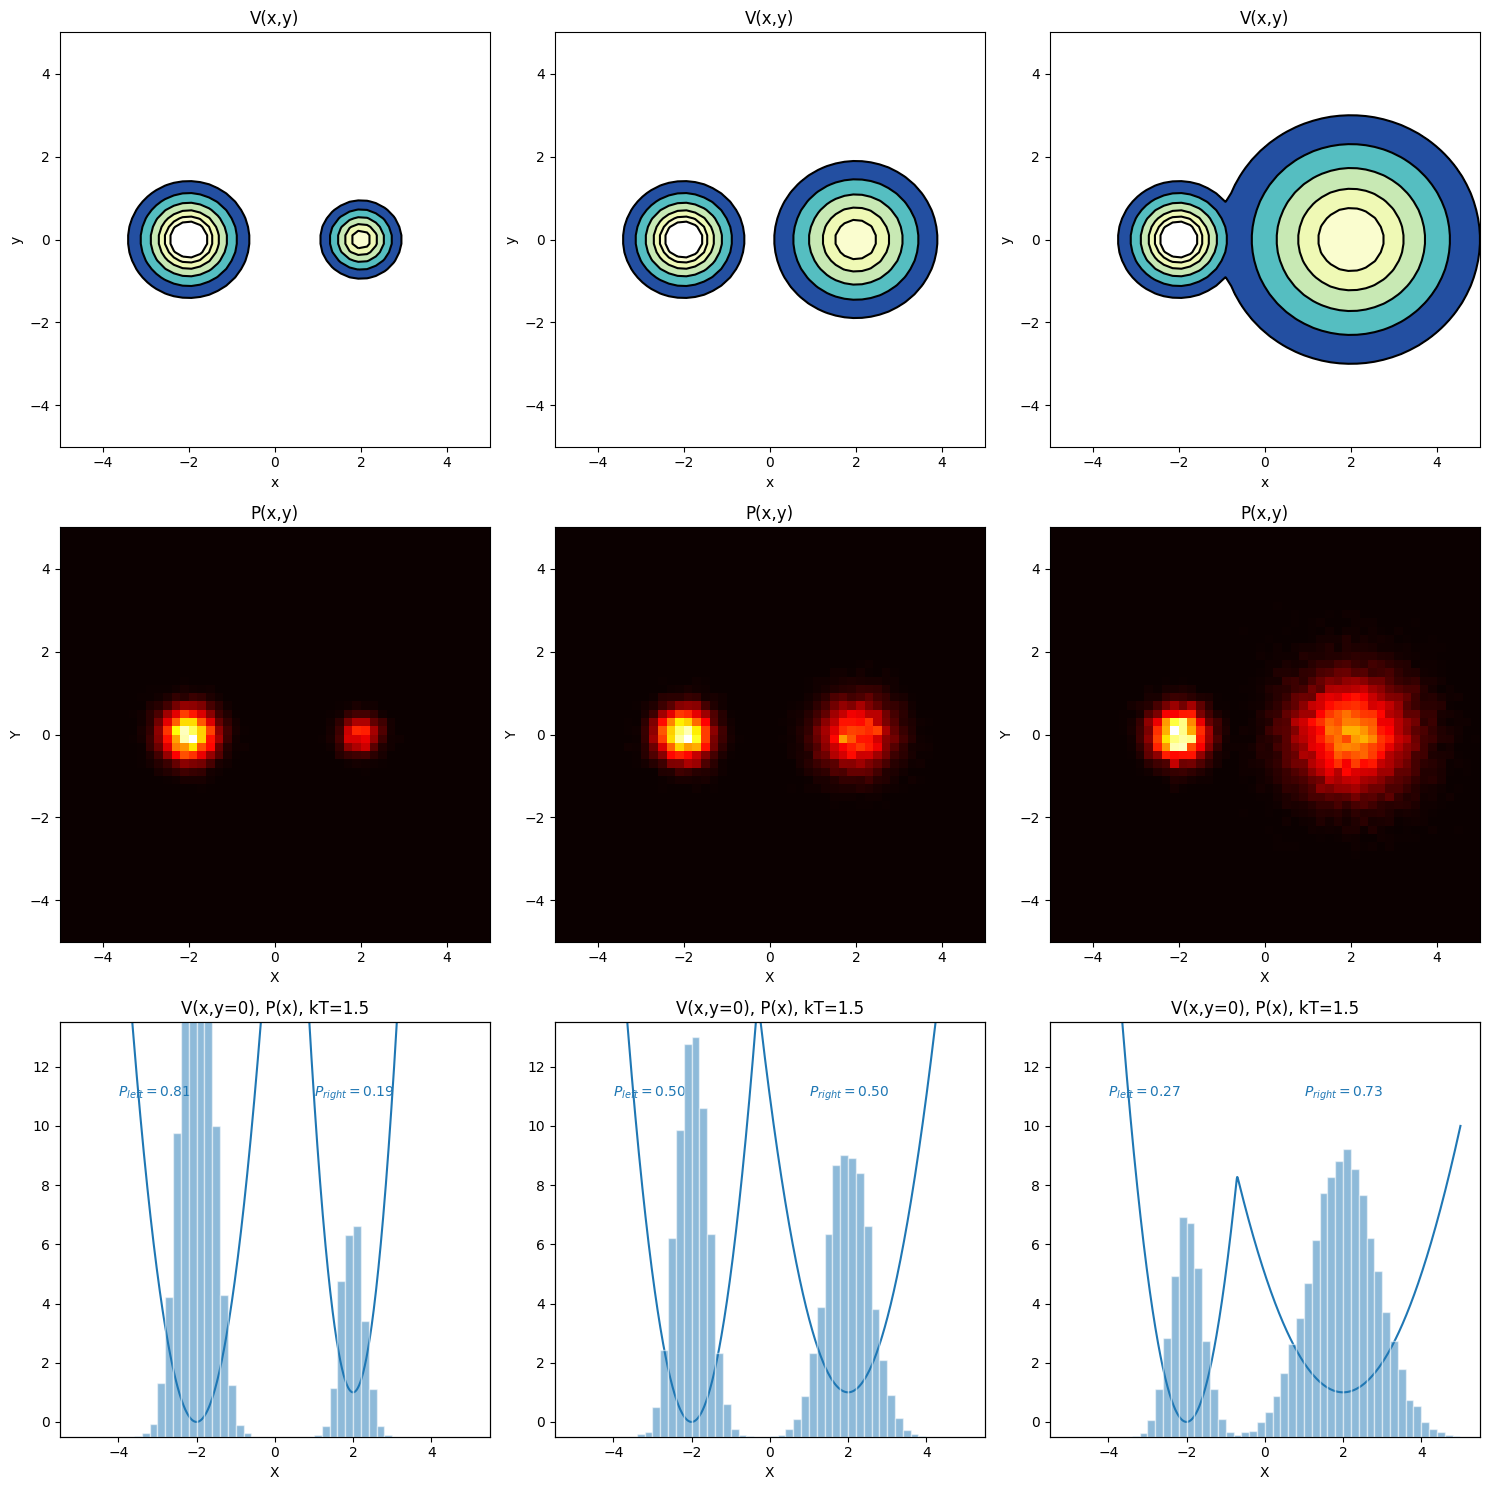

In [27]:
from Metropolis import *

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.transpose().flatten()
for i, k2 in enumerate(k2_vals):
    pot = Potential2D(k1x, k1y, k2, k2)
    met = Metropolis(calc=pot, initial_state=[0.0, 0.0], kT=kbT, step_size=1.0)
    pos, energies = met.run(n_steps=100_000)

    # Extract x and y arrays
    x_vals = pos[:, 0]
    y_vals = pos[:, 1]
    
    pot.contour_of_potential_energy(axes[3 * i])

    ax_h = axes[3 * i + 1]
    ax_h.hist2d(x_vals, y_vals, bins=50, range=[[-5, 5], [-5, 5]], cmap='hot')
    ax_h.set_title('P(x,y)')
    ax_h.set_xlabel('X')
    ax_h.set_ylabel('Y')


    # --- Bottom Row: P(x) Histogram and V(x, y=0) ---
    pot.plot1d(axes[3 * i + 2], x_vals)
    
    
plt.tight_layout()
plt.show()

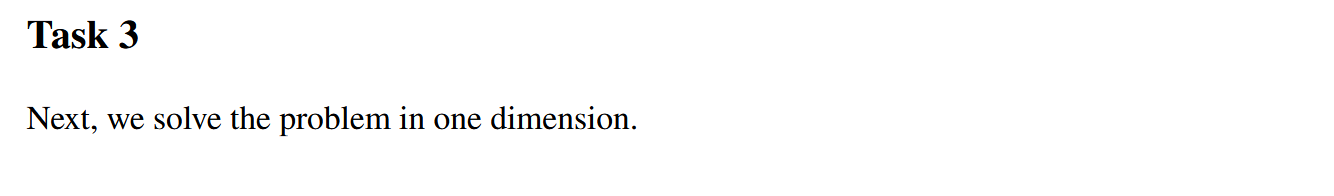
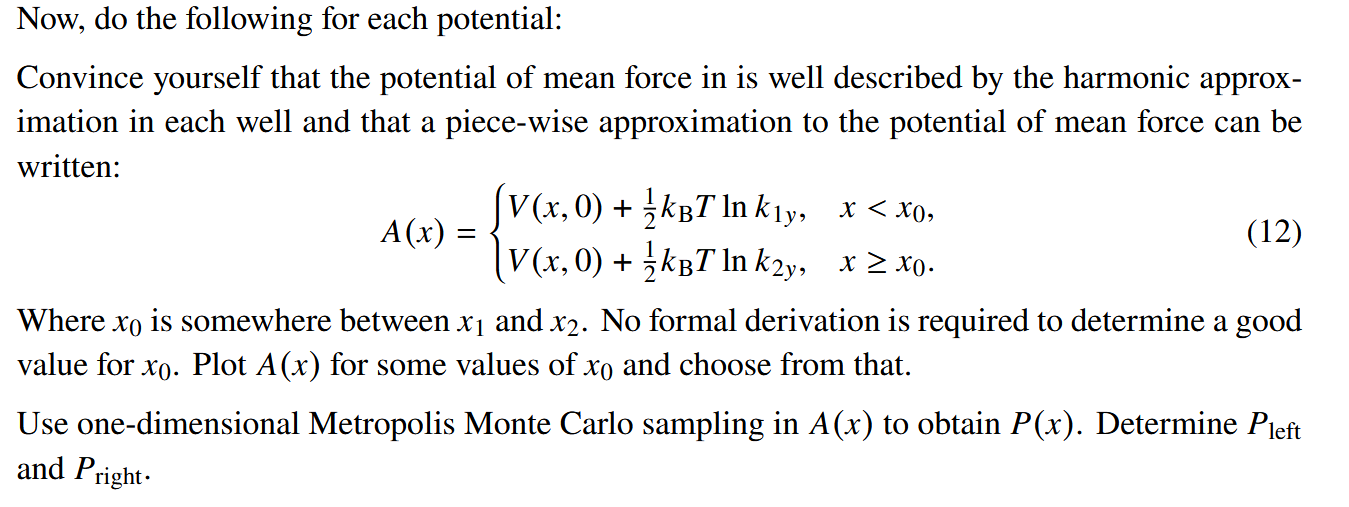

C:\Users\Moth\AppData\Local\Temp\ipykernel_18612\3653574842.py:36: RuntimeWarning: divide by zero encountered in log
  return -1/self.a * np.log(np.exp(-self.a*self.V1(x, y))


Sample size: 100000
Sample size: 100000
Sample size: 100000


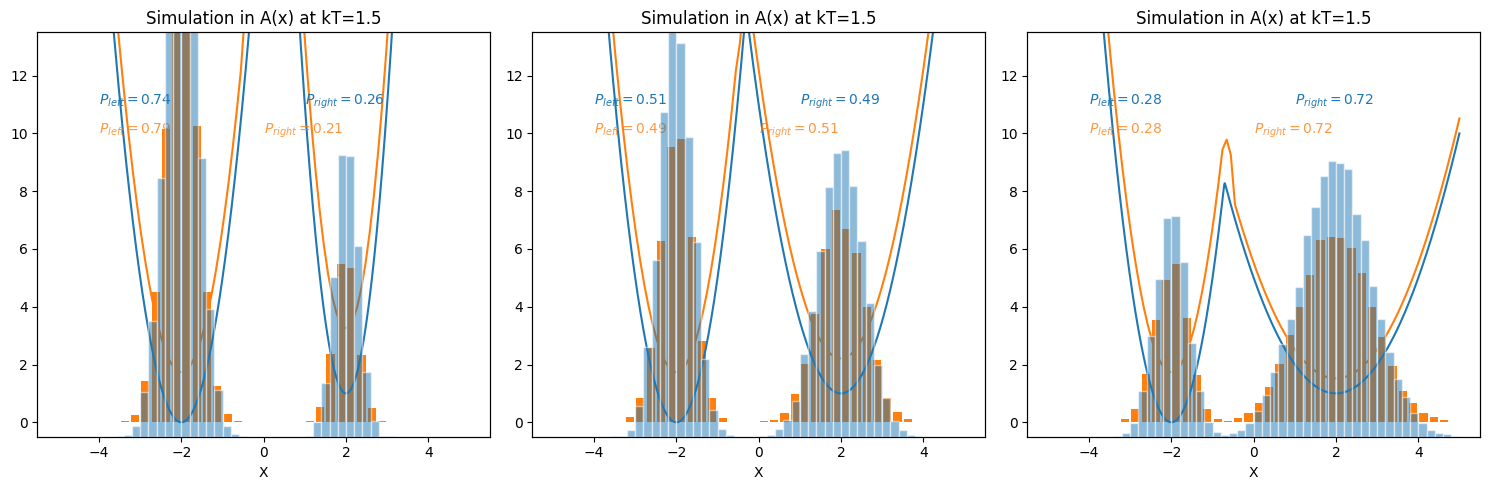

In [32]:
from scipy.interpolate import interp1d
from week06 import MonteCarlo1D

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, k2 in enumerate(k2_vals):
    pot = Potential2D(k1x, k1y, k2, k2)
    met = Metropolis(calc=pot, initial_state=[0.0, 0.0], kT=kbT, step_size=1.0)
    pos, energies = met.run(n_steps=100_000)
    x_vals = pos[:, 0]

    pot.plot1d(ax[i], x_vals)

    x0 = -0.5

    # Calculate A(x)
    a = lambda x: (pot.V([x, 0]) + 0.5 * kbT * np.log(k1y)) if x < x0 \
             else (pot.V([x, 0]) + 0.5 * kbT * np.log(k2))

    xs = np.linspace(*pot.limits()[0], 100)
    avals = [a(x) for x in xs]

    # Interpolate to create a fast, continuous function for the Monte Carlo sampler
    a_approx = interp1d(xs, avals)

    monte_carlo_for_A = MonteCarlo1D(
        a_approx, 
        Nsim=100_000, 
        transition_method='uniform', 
        kT=kbT
    )

    monte_carlo_for_A.plot(ax[i])

plt.tight_layout()    
plt.show()

In [33]:
for k2 in k2_vals:
    pot = Potential2D(k1x, k1y, k2, k2)
    F1 = pot.V([-2.0, 0]) + 0.5*kbT*np.log(k1x*k1y)
    F2 = pot.V([ 2.0, 0]) + 0.5*kbT*np.log(k2*k2)

    print(f'F1 = {F1:.3f}, F2 = {F2:.3f}')

F1 = 3.454, F2 = 5.494
F1 = 3.454, F2 = 3.414
F1 = 3.454, F2 = 2.040


### Why a Broader Well Can Have a Larger Equilibrium Population

* **Free Energy Minimization:** Systems in thermal equilibrium do not minimize their potential energy ($E$); they minimize their Helmholtz free energy ($F = E - TS$).
* **The Entropy Term:** In Equation 13, the harmonic spring constants ($k_x$ and $k_y$) represent the steepness of the well walls. A broader well has smaller $k$ values. Because the equation contains $\ln(k_x k_y)$, smaller spring constants result in a smaller (or more negative) entropic penalty, which directly lowers the free energy $F$.
* **Physical Meaning:** A broader well contains a vastly larger volume of accessible phase space (more microstates) for the walker to occupy, meaning it has much higher entropy.
* **Temperature Scaling:** At high enough temperatures (like $k_B T = 1.5$), the entropic reward ($-TS$) of sitting in a very wide well will overpower the potential energy penalty ($+E$) of the well's minimum being higher. Consequently, the high-energy, broad well achieves a lower overall free energy and dominates the equilibrium population.